In [18]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [19]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


Dataset Shape: (200000, 29)
     Record_ID                      Timestamp        Date  Hour  Month  \
0  REC_0000000  2024-03-14 17:35:06.841829282  2024-03-14    17      3   
1  REC_0000001  2023-05-25 08:10:56.398060108  2023-05-25     8      5   
2  REC_0000002  2023-11-07 08:25:17.721608262  2023-11-07     8     11   
3  REC_0000003  2024-07-24 09:30:00.947374674  2024-07-24     9      7   
4  REC_0000004  2024-04-03 09:34:07.316651267  2024-04-03     9      4   

  Day_of_Week   Time_of_Day  Is_Holiday Area_Type   Road_Type  ...  \
0    Thursday  Evening Peak           0     Urban  Interstate  ...   
1    Thursday  Morning Peak           0  Suburban  Interstate  ...   
2     Tuesday  Morning Peak           0  Suburban  Interstate  ...   
3   Wednesday  Morning Peak           0  Suburban   Collector  ...   
4   Wednesday  Morning Peak           0     Urban       Local  ...   

  Vehicle_Age_yrs  Recorded_Speed_kmh Baseline_Expected_Response_Time_min  \
0             7.2            

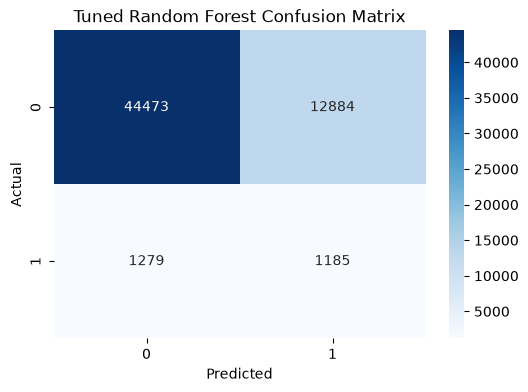

In [20]:

# =====================================================
# 1. IMPORT LIBRARIES
# =====================================================
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

import warnings
warnings.filterwarnings('ignore')


# =====================================================
# 2. LOAD DATASET
# =====================================================

df = pd.read_csv('C:\project\synthetic_traffic_benchmark_200k.csv')

print("Dataset Shape:", df.shape)
print(df.head())


# =====================================================
# 3. REMOVE DUPLICATES
# =====================================================

df.drop_duplicates(inplace=True)

print("After removing duplicates:", df.shape)


# =====================================================
# 4. HANDLE MISSING VALUES
# =====================================================

print("\nMissing values:")
print(df.isnull().sum())


# =====================================================
# 5. FEATURE ENGINEERING
# =====================================================

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df['Year'] = df['Date'].dt.year
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek

df.drop(
    columns=['Date', 'Timestamp', 'Record_ID'],
    errors='ignore',
    inplace=True
)


# =====================================================
# 6. REMOVE DATA LEAKAGE COLUMNS
# =====================================================

leakage_cols = [
    'Accident_Severity',
    'Vehicles_Involved',
    'Collision_Type',
    'Dispatch_Priority',
    'Actual_Response_Time_min',
    'Road_Closure_Duration_min'
]

df.drop(
    columns=leakage_cols,
    errors='ignore',
    inplace=True
)

print("\nRemaining columns:")
print(df.columns.tolist())


# =====================================================
# 7. SEPARATE X AND Y
# =====================================================

x = df.drop('Accident_Occurred', axis=1)

y = df['Accident_Occurred']

print("\nTarget distribution:")
print(y.value_counts())


# =====================================================
# 8. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# =====================================================

numeric_cols = x.select_dtypes(
    include=['int64', 'float64', 'bool']
).columns.tolist()

categorical_cols = x.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("\nNumerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)


# =====================================================
# 9. PREPROCESSING
# =====================================================

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])


# =====================================================
# 10. TRAIN TEST SPLIT
# =====================================================

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())


# =====================================================
# 11. CREATE CLASSIFICATION MODELS
# =====================================================


models = {

    "Logistic Regression": ImbPipeline([
        ('preprocessing', preprocessor),
        ('sampling', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

  "KNN": ImbPipeline([
    ('preprocessing', preprocessor),
    ('sampling', SMOTE(random_state=42)),
    ('classifier', KNeighborsClassifier(
        n_neighbors=15,
        weights='uniform',
        metric='euclidean',
        n_jobs=-1
    ))
]),

    "Decision Tree": ImbPipeline([
        ('preprocessing', preprocessor),
        ('sampling', SMOTE(random_state=42)),
        ('classifier', DecisionTreeClassifier(
            max_depth=6,
            min_samples_split=50,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

"Random Forest": ImbPipeline([
    ('preprocessing', preprocessor),
    ('sampling', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_split=50,
        min_samples_leaf=50,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

}



# =====================================================
# 12. TRAIN AND EVALUATE MODELS
# =====================================================


# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ==========================================
# 2. DEFINE RANDOM FOREST PIPELINE
# ==========================================

rf_pipeline = Pipeline([
    ('preprocessing', preprocessor),

    ('sampling', SMOTE(random_state=42)),

    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])


# ==========================================
# 3. DEFINE HYPERPARAMETERS
# ==========================================

param_grid = {
    'classifier__n_estimators': [100, 200, 300],

    'classifier__max_depth': [5, 8, 10, 15, None],

    'classifier__min_samples_split': [10, 20, 50],

    'classifier__min_samples_leaf': [10, 20, 30, 50],

    'classifier__max_features': ['sqrt', 'log2']
}


# ==========================================
# 4. RANDOMIZED SEARCH CV
# ==========================================

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,

    param_distributions=param_grid,

    n_iter=10,

    scoring='f1',

    cv=3,

    random_state=42,

    n_jobs=-1,

    verbose=2
)


# ==========================================
# 5. TRAIN THE MODEL
# ==========================================

print("Hyperparameter tuning started...")

random_search.fit(x_train, y_train)

print("Hyperparameter tuning completed!")


# ==========================================
# 6. DISPLAY BEST PARAMETERS
# ==========================================

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search.best_score_)


# ==========================================
# 7. SELECT BEST MODEL
# ==========================================

best_model = random_search.best_estimator_


# ==========================================
# 8. PREDICTION
# ==========================================

y_pred = best_model.predict(x_test)


# ==========================================
# 9. MODEL EVALUATION
# ==========================================

print("\n========== TUNED RANDOM FOREST RESULTS ==========")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))


# ==========================================
# 10. CLASSIFICATION REPORT
# ==========================================

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


# ==========================================
# 11. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Tuned Random Forest Confusion Matrix")

plt.show()


In [24]:
y_pred

array([0, 0, 1, ..., 1, 0, 1], shape=(59821,))

In [25]:
best_model

,steps,"[('preprocessing', ...), ('sampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](22,)","['Hour','Month','Day_of_Week',...,'Year','Day','DayOfWeek']"
n_features_in_,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [21]:
pip install streamlit

   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   --------- ------------------------------ 2.4/10.4 MB 11.6 MB/s eta 0:00:01
   ------------------- -------------------- 5.0/10.4 MB 11.7 MB/s eta 0:00:01
   ---------------------------- ----------- 7.3/10.4 MB 11.7 MB/s eta 0:00:01
   -------------------------------------- - 10.0/10.4 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 10.4/10.4 MB 10.9 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 9.0 MB/s  0:00:00
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   -- ------------------------------------- 2.1/29.2 MB 11.7 MB/s eta 0:00:03
   ------ --------------------------------- 4.7/29.2 MB 11.7 MB/s eta 0:00:03
   --------- ------------------------------ 7.1/29.2 MB 11.7 MB/s eta 0:00:02
   ------------ --------------------------- 9.4/29.2 MB 11.7 MB/s eta 0:00:02
   --------

In [22]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [23]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [27]:
model=best_model

In [28]:
import joblib
joblib.dump(model,'accident_detection.pkl')

['accident_detection.pkl']

In [ ]:
joblib.dump(scaler,'scaler.pkl')